# Damped pendulum ODE conditioning of GP regression

This notebook fits a GP to noisy measurements of a damped pendulum's angle $\theta(t)$, then conditions its samples to obey the nonlinear pendulum ODE

$$\ddot{\theta} + \beta \dot{\theta} + \sin(\theta) = 0, \qquad \beta = 0.2.$$

The GP prior specifies only smoothness; the ODE, imposed as a condition on a finite-difference residual, adds the physics. The notebook shows that guidance alone, with no change to the GP, pulls the samples towards solutions of the ODE.

## 1. Setup

The record is `t_final` = 30 seconds long, sampled on `N` grid points. Time is divided by `t_final` so the GP works on $[0, 1)$, while the ODE residual uses the physical step `dt`.

In [1]:
import pickle
import sys
from pathlib import Path

import gpytorch
import numpy as np
import torch

from flow_inference.conditions import EqualityCondition
from flow_inference.flow_utils import build_grid_in_box
from flow_inference.flows import GaussianProcessFlow
from flow_inference.gp_utils import fit_kernel_hyperparameters, gp_posterior
from flow_inference.guidance import GuidanceMC
from flow_inference.sampler import IntegratorSampler

sys.path.insert(0, str(Path.cwd().parent))  # examples/, for plotting.py
from plotting import plot_paths

/home/henry/Documents/python_dev/flow-inference/.venv/lib/python3.12/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


In [2]:
device = "cuda" if torch.cuda.is_available() else "cpu"
N = 128              # grid points
t_final = 30.0       # record length in seconds
dt = t_final / N     # physical grid spacing, used by the ODE residual
noise = 0.01**2      # observation noise variance
num_samples = 25

## 2. Data and GP posterior

### 2.1 Data

The training data are noisy angle measurements stored in `examples/data/pendulum_train.pickle`. Their times are rescaled to $[0, 1)$.

In [3]:
with open("../data/pendulum_train.pickle", "rb") as f:
    train_data = pickle.load(f)
x = np.array(train_data["train"]["X"].tolist())[:, 0]
y = np.array(train_data["train"]["Y"].tolist())[:, 0]
X = torch.tensor(x).unsqueeze(-1).to(device) / t_final  # (M, 1), in [0, 1)
Y = torch.tensor(y).to(device)                          # (M,)

### 2.2 GP posterior

The RBF kernel's lengthscale and outputscale are fitted to the data by type-II maximum likelihood, starting from the values set below. `gp_posterior` then forms the conjugate posterior, whose mean and kernel the flow evaluates on the grid.

In [4]:
coords = build_grid_in_box(N, 1, device)  # (N, 1)
kernel = gpytorch.kernels.ScaleKernel(gpytorch.kernels.RBFKernel()).to(device)
kernel.base_kernel.lengthscale = 1.0
kernel.outputscale = 0.1
kernel = fit_kernel_hyperparameters(X_train=X, y_train=Y, kernel=kernel, noise=noise, device=device)
p0_mean_fn, p0_kernel = gp_posterior(kernel, X, Y, noise=noise)
print(f"type-II ML: lengthscale {kernel.base_kernel.lengthscale.item():.4f}, "
      f"outputscale {kernel.outputscale.item():.4f}")

fitting kernel:   0%|          | 0/500 [00:00<?, ?it/s]

type-II ML: lengthscale 0.0530, outputscale 1.0240


### 2.3 Prior samples

Samples from the GP posterior alone, before the ODE is imposed. `plotter` draws a band and a few sample paths, with the observations in red.

  0%|          | 0/999 [00:00<?, ?it/s]

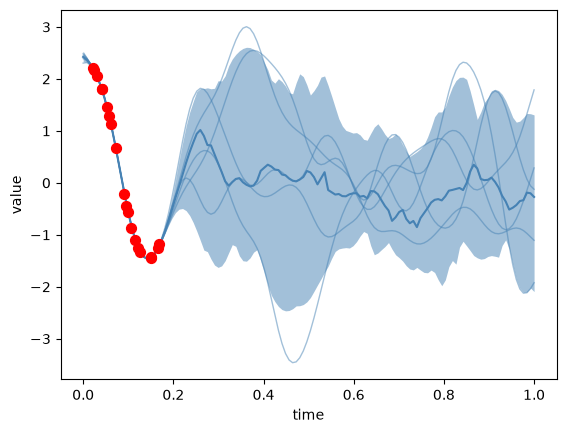

In [5]:
def plotter(samples, num_samples=10):
    ax, _ = plot_paths(samples, num_samples=num_samples)
    ax.scatter(X.squeeze(-1).cpu().numpy(), Y.cpu().numpy(), color="red", s=50, zorder=5)


flow = GaussianProcessFlow(p0_kernel, p0_mean_fn, coords, device=device)
sampler = IntegratorSampler(flow=flow)
torch.manual_seed(1234)
samples_prior = sampler.sample(num_samples, num_steps=1_000)
plotter(samples_prior, num_samples=5)

## 3. Pendulum ODE condition

`PendulumCondition` is an `EqualityCondition` on the residual

$$r = \ddot\theta + \beta\dot\theta + \sin\theta,$$

with both derivatives computed by centred differences at the interior grid points. An `EqualityCondition` scores a residual with a Gaussian log-likelihood. Because the residual is evaluated at every interior time step, the condition passes the step `dt` as quadrature `weights`, so the log-likelihood is

$$-\frac{1}{2\sigma^2}\sum_i r_i^2\,\Delta t \;\approx\; -\frac{1}{2\sigma^2}\int r(t)^2\,dt.$$

$\sigma$ is then a tolerance on the root-mean-square ODE residual over the record, and it means the same thing at any resolution: without the weights, doubling `N` would double the number of penalty terms and enforce the ODE more tightly. $\sigma = 5\times10^{-3}$ below corresponds to a per-step tolerance of $10^{-2}$ at `N = 128`.

In [6]:
class PendulumCondition(EqualityCondition):
    """Damped pendulum ODE residual for a single-channel field on a uniform time grid."""

    def __init__(self, dt: float, sigma: float = 1.0, beta: float = 0.2):
        super().__init__(sigma=sigma, weights=dt)  # quadrature weight: one time step
        self.dt = float(dt)
        self.register_buffer("beta", torch.tensor(float(beta)))  # damping coefficient

    def residual(self, x: torch.Tensor) -> torch.Tensor:
        theta = x.squeeze(1)  # (B, N)
        # Centred differences at the interior points 1..N-2.
        dtheta_dt = (theta[:, 2:] - theta[:, :-2]) / (2 * self.dt)
        d2theta_dt2 = (theta[:, 2:] - 2 * theta[:, 1:-1] + theta[:, :-2]) / (self.dt * self.dt)
        residual = d2theta_dt2 + torch.sin(theta[:, 1:-1]) + self.beta * dtheta_dt
        return residual.unsqueeze(1)  # (B, 1, N-2)


condition = PendulumCondition(dt, sigma=5e-3, beta=0.2).to(device)

## 4. Conditioned sampling

`GuidanceMC` estimates the guidance term at each step by drawing Monte Carlo samples of the clean path given the current state, and weighting their log-likelihood gradients. Here it uses 100 draws per step for a low-variance estimate, and raises `max_norm`, the level at which the size of the guidance term is softly capped, from its default of $10^2$ to $10^3$.

  0%|          | 0/999 [00:00<?, ?it/s]

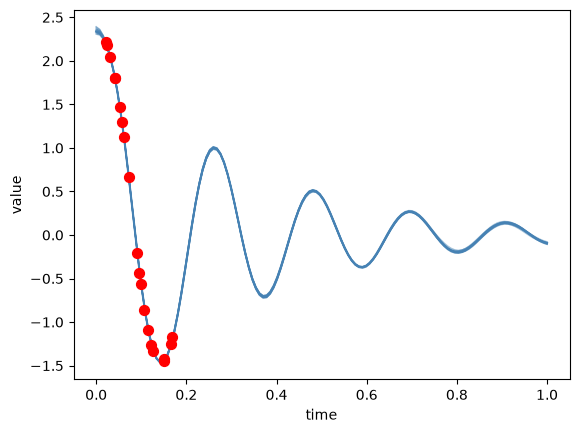

In [7]:
guidance = GuidanceMC(flow, condition, num_mc_samples=100, max_norm=1e3).to(device)
samples = sampler.sample(num_samples, guidance=guidance, num_steps=1_000)
plotter(samples)

## 5. Summary

* A physical law enters as an `EqualityCondition` on its finite-difference residual; the GP itself is unchanged.
* Weighting the residual by the time step makes $\sigma$ a tolerance on the root-mean-square residual, independent of the grid size.
* Compare Section 4 with the prior samples in Section 2.3: the conditioned paths should still pass near the observations, while their oscillations follow the damped pendulum dynamics rather than only the GP's smoothness.